In [34]:
!pip install -q torchmetrics imbalanced-learn seaborn scikit-learn matplotlib

In [35]:
import warnings
warnings.filterwarnings("ignore")

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    matthews_corrcoef, cohen_kappa_score, balanced_accuracy_score,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    log_loss, brier_score_loss
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

In [36]:
drive.mount('/content/gdrive')
DATASET_PATH = "/content/gdrive/MyDrive/dataset/postnatal_data.csv"

df = pd.read_csv(DATASET_PATH)

print("Shape:", df.shape)
print("\nColumns:\n", df.columns.tolist())
print("\nFirst 5 rows:")
display(df.head())
print("\nMissing values:\n", df.isnull().sum())

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Shape: (1503, 11)

Columns:
 ['Timestamp', 'Age', 'Feeling sad or Tearful', 'Irritable towards baby & partner', 'Trouble sleeping at night', 'Problems concentrating or making decision', 'Overeating or loss of appetite', 'Feeling anxious', 'Feeling of guilt', 'Problems of bonding with baby', 'Suicide attempt']

First 5 rows:


,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No
3,6/14/2022 20:05,35-40,Yes,Yes,Yes,Yes,No,Yes,Maybe,No,No
4,6/14/2022 20:06,40-45,Yes,No,Two or more days a week,Yes,No,Yes,No,Yes,No



Missing values:
 Timestamp                                     0
Age                                           0
Feeling sad or Tearful                        0
Irritable towards baby & partner              6
Trouble sleeping at night                     0
Problems concentrating or making decision    12
Overeating or loss of appetite                0
Feeling anxious                               0
Feeling of guilt                              9
Problems of bonding with baby                 0
Suicide attempt                               0
dtype: int64


In [37]:
print("\nData types:\n", df.dtypes)

for col in df.columns:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))


Data types:
 Timestamp                                    object
Age                                          object
Feeling sad or Tearful                       object
Irritable towards baby & partner             object
Trouble sleeping at night                    object
Problems concentrating or making decision    object
Overeating or loss of appetite               object
Feeling anxious                              object
Feeling of guilt                             object
Problems of bonding with baby                object
Suicide attempt                              object
dtype: object

Column: Timestamp
Timestamp
6/15/2022 22:24    51
6/14/2022 22:19    43
6/15/2022 0:29     35
6/15/2022 0:31     35
6/15/2022 0:27     35
                   ..
6/14/2022 20:11     5
6/14/2022 20:03     4
6/14/2022 20:02     4
6/14/2022 20:04     4
6/14/2022 20:05     4
Name: count, Length: 90, dtype: int64

Column: Age
Age
40-45    364
35-40    349
30-35    338
45-50    271
25-30    181
Name: cou

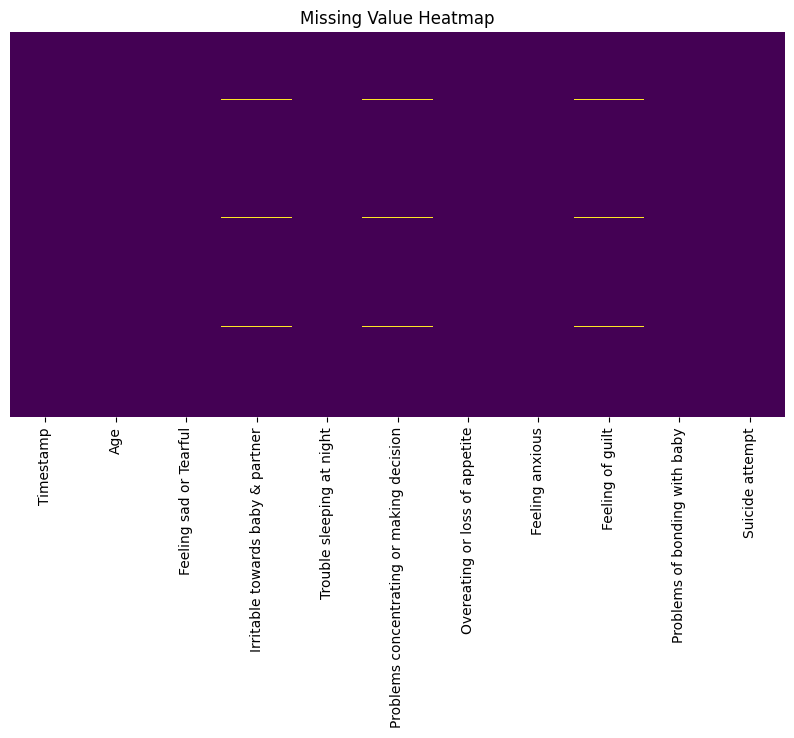

In [38]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Value Heatmap")
plt.show()

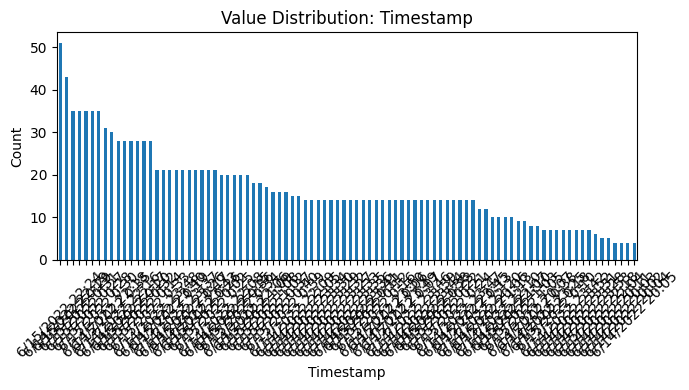

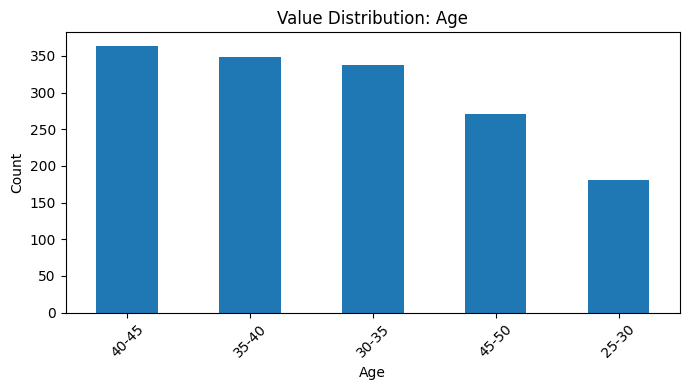

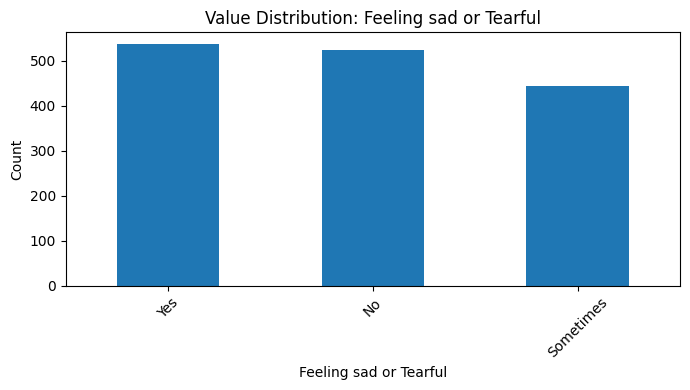

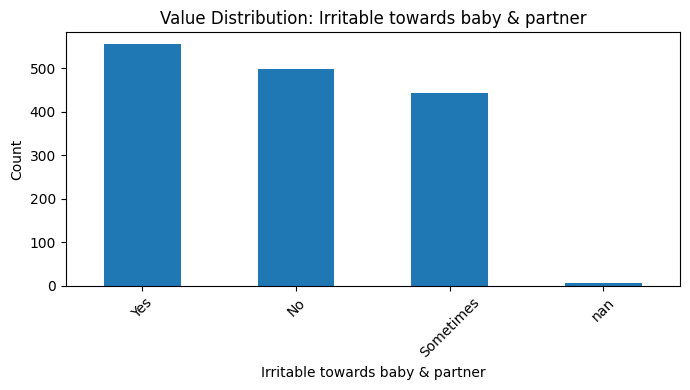

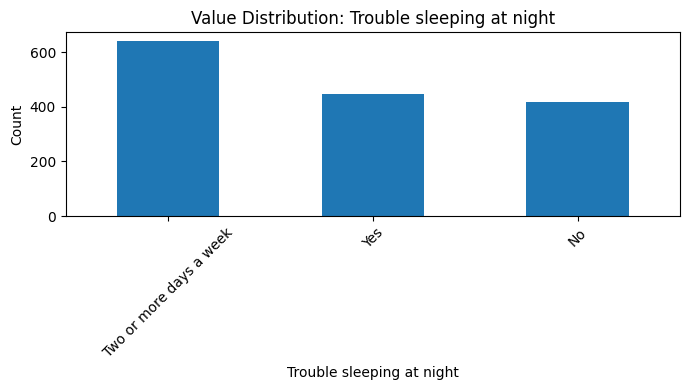

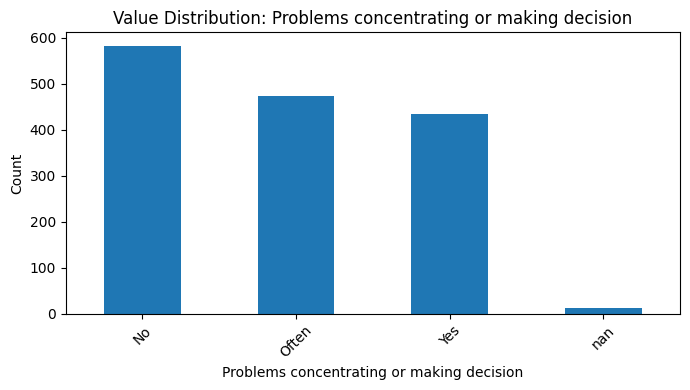

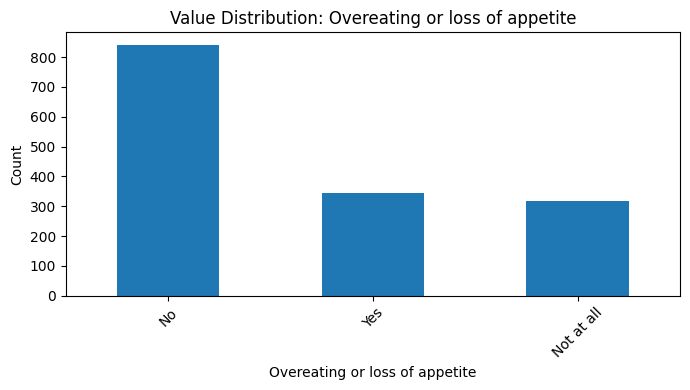

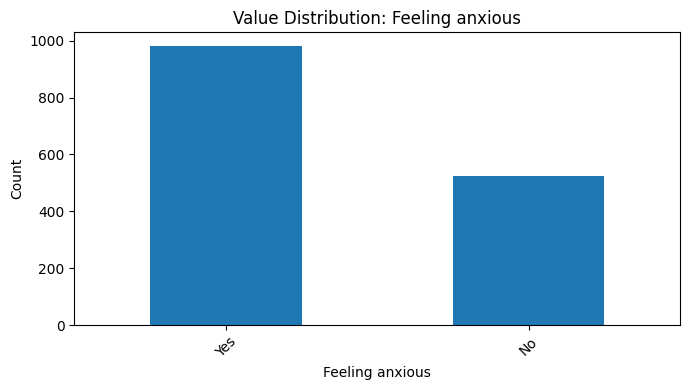

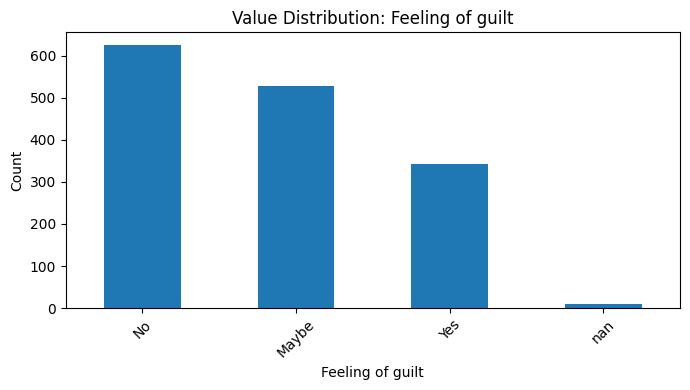

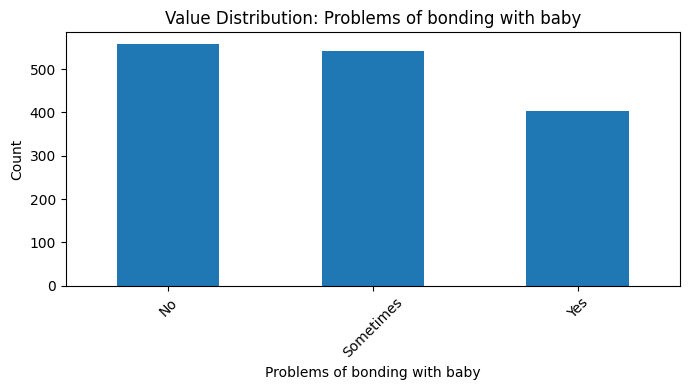

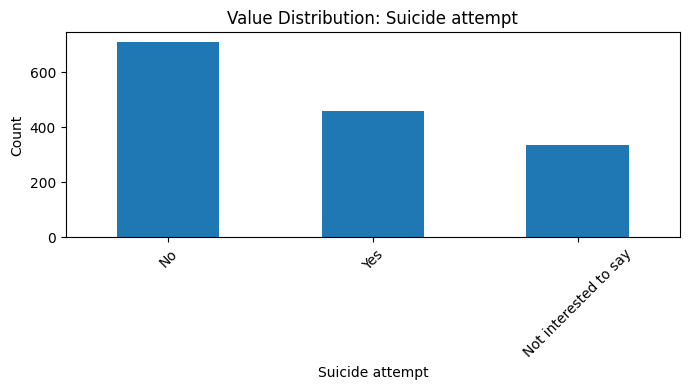

In [39]:
for col in df.columns:
    plt.figure(figsize=(7, 4))
    df[col].astype(str).value_counts().plot(kind='bar')
    plt.title(f"Value Distribution: {col}")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [40]:
target_column = "Suicide attempt"   # Change if needed

print("Target distribution:")
print(df[target_column].value_counts())

Target distribution:
Suicide attempt
No                       709
Yes                      459
Not interested to say    335
Name: count, dtype: int64


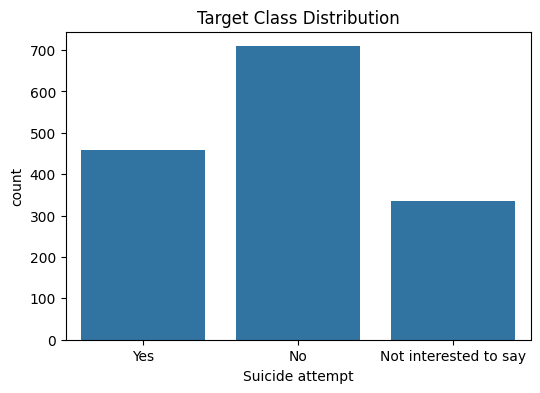

In [41]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df[target_column])
plt.title("Target Class Distribution")
plt.show()

In [42]:
df_model = df.copy()

# Remove timestamp-like column if present
drop_cols = []
for col in df_model.columns:
    if "timestamp" in col.lower():
        drop_cols.append(col)

if drop_cols:
    df_model = df_model.drop(columns=drop_cols)
    print("Dropped columns:", drop_cols)

# Fill missing values
for col in df_model.columns:
    df_model[col] = df_model[col].fillna(df_model[col].mode()[0])

# Ordinal mapping for symptom responses
ordinal_map = {
    "No": 0,
    "Sometimes": 1,
    "Yes": 2,
    "no": 0,
    "sometimes": 1,
    "yes": 2
}

label_encoders = {}

for col in df_model.columns:
    if df_model[col].dtype == object:
        unique_vals = set(df_model[col].astype(str).unique())
        if unique_vals.issubset(set(ordinal_map.keys())):
            df_model[col] = df_model[col].astype(str).map(ordinal_map)
        else:
            le = LabelEncoder()
            df_model[col] = le.fit_transform(df_model[col].astype(str))
            label_encoders[col] = le

print(df_model.head())

Dropped columns: ['Timestamp']
   Age  Feeling sad or Tearful  Irritable towards baby & partner  \
0    2                       2                                 2   
1    3                       2                                 0   
2    2                       2                                 0   
3    2                       2                                 2   
4    3                       2                                 0   

   Trouble sleeping at night  Problems concentrating or making decision  \
0                          1                                          2   
1                          0                                          2   
2                          2                                          2   
3                          2                                          2   
4                          1                                          2   

   Overeating or loss of appetite  Feeling anxious  Feeling of guilt  \
0                               2    

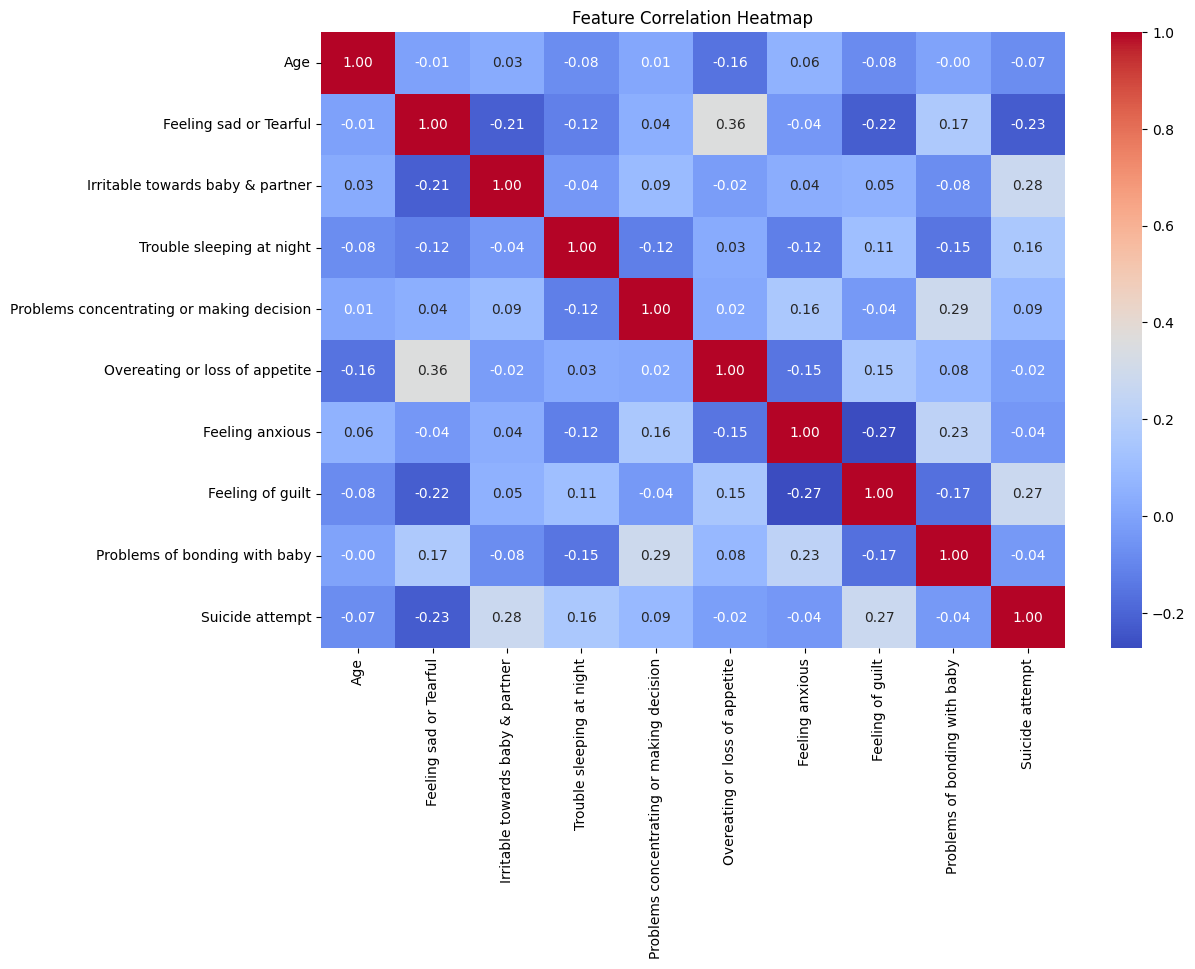

In [43]:
plt.figure(figsize=(12, 8))
corr = df_model.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

Suicide attempt                              1.000000
Irritable towards baby & partner             0.277915
Feeling of guilt                             0.274441
Trouble sleeping at night                    0.156737
Problems concentrating or making decision    0.089298
Overeating or loss of appetite              -0.018513
Problems of bonding with baby               -0.037258
Feeling anxious                             -0.040325
Age                                         -0.074603
Feeling sad or Tearful                      -0.225143
Name: Suicide attempt, dtype: float64


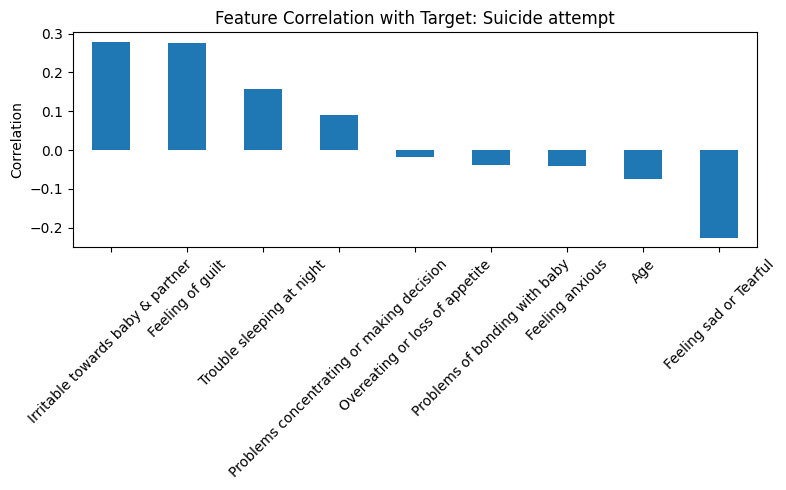

In [44]:
target_corr = corr[target_column].sort_values(ascending=False)
print(target_corr)

plt.figure(figsize=(8, 5))
target_corr.drop(target_column).plot(kind='bar')
plt.title(f"Feature Correlation with Target: {target_column}")
plt.ylabel("Correlation")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
X = df_model.drop(columns=[target_column])
y = df_model[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (1202, 9)
X_test : (301, 9)


In [46]:
print("Before SMOTE:", np.bincount(y_train))

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("After SMOTE :", np.bincount(y_train_res))

Before SMOTE: [567 268 367]
After SMOTE : [567 567 567]


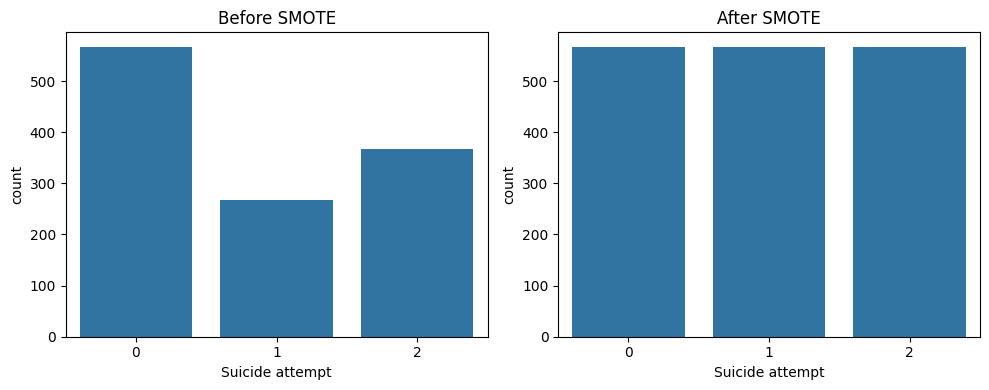

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")

sns.countplot(x=y_train_res, ax=axes[1])
axes[1].set_title("After SMOTE")

plt.tight_layout()
plt.show()

In [48]:
import torch
from torch.utils.data import Dataset, DataLoader

# tensors
X_train_tensor = torch.tensor(X_train_res.values, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_res.values, dtype=torch.long)
y_test_tensor  = torch.tensor(y_test.values, dtype=torch.long)

# dataset class
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# loaders
train_dataset = TabularDataset(X_train_tensor, y_train_tensor)
test_dataset  = TabularDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("X_train_tensor:", X_train_tensor.shape)
print("X_test_tensor :", X_test_tensor.shape)
print("y_train_tensor:", y_train_tensor.shape)
print("y_test_tensor :", y_test_tensor.shape)

X_train_tensor: torch.Size([1701, 9])
X_test_tensor : torch.Size([301, 9])
y_train_tensor: torch.Size([1701])
y_test_tensor : torch.Size([301])


In [49]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

class ResidualBlock(nn.Module):
    def __init__(self, dim, dropout=0.2):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, dim * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim * 2, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return x + self.block(x)


class FeatureTokenizerNet(nn.Module):
    def __init__(self, input_dim, num_classes, emb_dim=128, num_blocks=4, dropout=0.25):
        super().__init__()

        self.feature_proj = nn.Sequential(
            nn.Linear(input_dim, emb_dim),
            nn.LayerNorm(emb_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        self.res_blocks = nn.Sequential(
            *[ResidualBlock(emb_dim, dropout=dropout) for _ in range(num_blocks)]
        )

        self.gate = nn.Sequential(
            nn.Linear(emb_dim, emb_dim),
            nn.Sigmoid()
        )

        self.head = nn.Sequential(
            nn.LayerNorm(emb_dim),
            nn.Linear(emb_dim, emb_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(emb_dim // 2, num_classes)
        )

    def forward(self, x):
        x = self.feature_proj(x)
        x = self.res_blocks(x)
        g = self.gate(x)
        x = x * g
        x = self.head(x)
        return x


# device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# IMPORTANT: use actual tensor feature size
print("X_train_tensor shape:", X_train_tensor.shape)
print("X_test_tensor shape :", X_test_tensor.shape)

input_dim = X_train_tensor.shape[1]
num_classes = len(np.unique(y_train_tensor.numpy()))

print("Input dim:", input_dim)
print("Num classes:", num_classes)

model = FeatureTokenizerNet(
    input_dim=input_dim,
    num_classes=num_classes,
    emb_dim=128,
    num_blocks=5,
    dropout=0.25
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.0008, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=3, factor=0.5
)

num_epochs = 50
best_val_acc = 0.0
patience = 7
patience_counter = 0

train_losses = []
val_losses = []
train_accs = []
val_accs = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()

        running_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        correct_train += (preds == yb).sum().item()
        total_train += yb.size(0)

    train_loss = running_loss / len(train_loader)
    train_acc = correct_train / total_train

    model.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)

            outputs = model(xb)
            loss = criterion(outputs, yb)

            running_val_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            correct_val += (preds == yb).sum().item()
            total_val += yb.size(0)

    val_loss = running_val_loss / len(test_loader)
    val_acc = correct_val / total_val

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    scheduler.step(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}] | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), "best_feature_tokenizer_model.pth")
    else:
        patience_counter += 1

    if patience_counter >= patience:
        print("Early stopping triggered.")
        break

# load best model AFTER training
model.load_state_dict(torch.load("best_feature_tokenizer_model.pth", map_location=device))
model.eval()

all_preds = []
all_probs = []
all_labels = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        outputs = model(xb)
        probs = torch.softmax(outputs, dim=1)

        preds = torch.argmax(probs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(yb.numpy())

all_preds = np.array(all_preds)
all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

print("Predictions shape:", all_preds.shape)
print("Probabilities shape:", all_probs.shape)
print("Labels shape:", all_labels.shape)

Using device: cpu
X_train_tensor shape: torch.Size([1701, 9])
X_test_tensor shape : torch.Size([301, 9])
Input dim: 9
Num classes: 3
Epoch [1/50] | Train Loss: 0.9907 | Train Acc: 0.5109 | Val Loss: 0.8704 | Val Acc: 0.6578
Epoch [2/50] | Train Loss: 0.8857 | Train Acc: 0.5908 | Val Loss: 0.8390 | Val Acc: 0.6013
Epoch [3/50] | Train Loss: 0.7773 | Train Acc: 0.6514 | Val Loss: 0.6784 | Val Acc: 0.6877
Epoch [4/50] | Train Loss: 0.6894 | Train Acc: 0.7166 | Val Loss: 0.5858 | Val Acc: 0.7375
Epoch [5/50] | Train Loss: 0.6154 | Train Acc: 0.7449 | Val Loss: 0.5457 | Val Acc: 0.7807
Epoch [6/50] | Train Loss: 0.5824 | Train Acc: 0.7549 | Val Loss: 0.5552 | Val Acc: 0.7608
Epoch [7/50] | Train Loss: 0.5506 | Train Acc: 0.7772 | Val Loss: 0.4457 | Val Acc: 0.7940
Epoch [8/50] | Train Loss: 0.4610 | Train Acc: 0.8131 | Val Loss: 0.4142 | Val Acc: 0.8472
Epoch [9/50] | Train Loss: 0.4314 | Train Acc: 0.8266 | Val Loss: 0.3801 | Val Acc: 0.8372
Epoch [10/50] | Train Loss: 0.4321 | Train Acc: 

In [50]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, matthews_corrcoef,
    cohen_kappa_score, balanced_accuracy_score, roc_auc_score,
    roc_curve, auc, precision_recall_curve, average_precision_score,
    log_loss
)
from sklearn.preprocessing import label_binarize
from sklearn.calibration import calibration_curve

# -------------------- BASIC METRICS --------------------
acc = accuracy_score(all_labels, all_preds)
prec_w = precision_score(all_labels, all_preds, average='weighted')
rec_w = recall_score(all_labels, all_preds, average='weighted')
f1_w = f1_score(all_labels, all_preds, average='weighted')
f1_macro = f1_score(all_labels, all_preds, average='macro')
f1_micro = f1_score(all_labels, all_preds, average='micro')
bal_acc = balanced_accuracy_score(all_labels, all_preds)
mcc = matthews_corrcoef(all_labels, all_preds)
kappa = cohen_kappa_score(all_labels, all_preds)
ll = log_loss(all_labels, all_probs)

print("========== Overall Metrics ==========")
print(f"Accuracy               : {acc:.4f}")
print(f"Precision (Weighted)   : {prec_w:.4f}")
print(f"Recall (Weighted)      : {rec_w:.4f}")
print(f"F1-score (Weighted)    : {f1_w:.4f}")
print(f"F1-score (Macro)       : {f1_macro:.4f}")
print(f"F1-score (Micro)       : {f1_micro:.4f}")
print(f"Balanced Accuracy      : {bal_acc:.4f}")
print(f"Matthews Corrcoef      : {mcc:.4f}")
print(f"Cohen Kappa            : {kappa:.4f}")
print(f"Log Loss               : {ll:.4f}")

# multiclass ROC-AUC
num_classes = all_probs.shape[1]
if num_classes == 2:
    roc_auc_ovr = roc_auc_score(all_labels, all_probs[:, 1])
    print(f"ROC-AUC                : {roc_auc_ovr:.4f}")
else:
    roc_auc_ovr = roc_auc_score(all_labels, all_probs, multi_class='ovr')
    roc_auc_ovo = roc_auc_score(all_labels, all_probs, multi_class='ovo')
    print(f"ROC-AUC (OvR)          : {roc_auc_ovr:.4f}")
    print(f"ROC-AUC (OvO)          : {roc_auc_ovo:.4f}")

print("\n========== Classification Report ==========")
print(classification_report(all_labels, all_preds))

========== Overall Metrics ==========
Accuracy               : 0.9668
Precision (Weighted)   : 0.9673
Recall (Weighted)      : 0.9668
F1-score (Weighted)    : 0.9669
F1-score (Macro)       : 0.9670
F1-score (Micro)       : 0.9668
Balanced Accuracy      : 0.9701
Matthews Corrcoef      : 0.9481
Cohen Kappa            : 0.9478
Log Loss               : 0.1252
ROC-AUC (OvR)          : 0.9962
ROC-AUC (OvO)          : 0.9963

========== Classification Report ==========
              precision    recall  f1-score   support

           0       0.99      0.96      0.97       142
           1       0.97      0.99      0.98        67
           2       0.94      0.97      0.95        92

    accuracy                           0.97       301
   macro avg       0.96      0.97      0.97       301
weighted avg       0.97      0.97      0.97       301



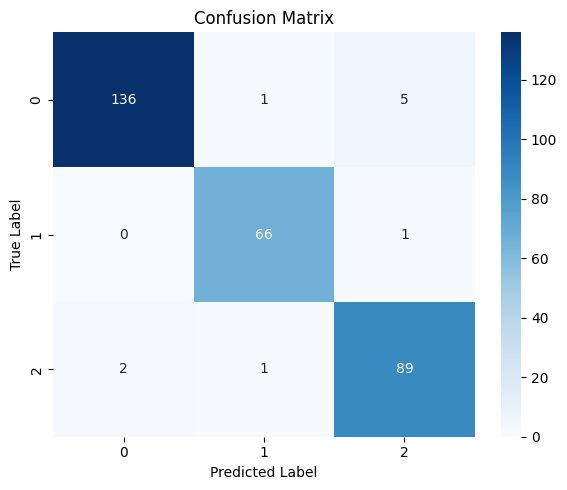

In [51]:
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [52]:
cm = confusion_matrix(all_labels, all_preds)
num_classes = cm.shape[0]

print("========== Per-Class Sensitivity and Specificity ==========")
for i in range(num_classes):
    TP = cm[i, i]
    FN = cm[i, :].sum() - TP
    FP = cm[:, i].sum() - TP
    TN = cm.sum() - (TP + FN + FP)

    sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0

    print(f"Class {i}: Sensitivity = {sensitivity:.4f}, Specificity = {specificity:.4f}")

========== Per-Class Sensitivity and Specificity ==========
Class 0: Sensitivity = 0.9577, Specificity = 0.9874
Class 1: Sensitivity = 0.9851, Specificity = 0.9915
Class 2: Sensitivity = 0.9674, Specificity = 0.9713


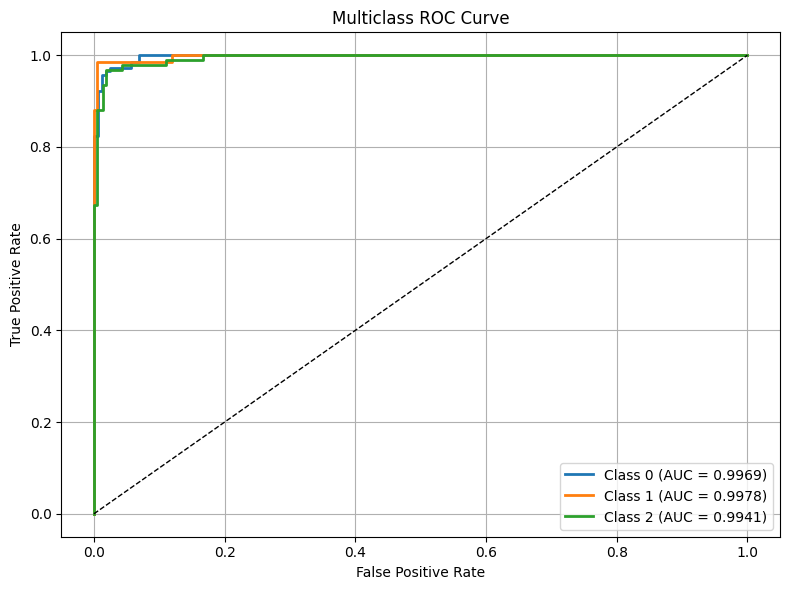

In [53]:
num_classes = all_probs.shape[1]
y_bin = label_binarize(all_labels, classes=np.arange(num_classes))

plt.figure(figsize=(8, 6))

for i in range(num_classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f"Class {i} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

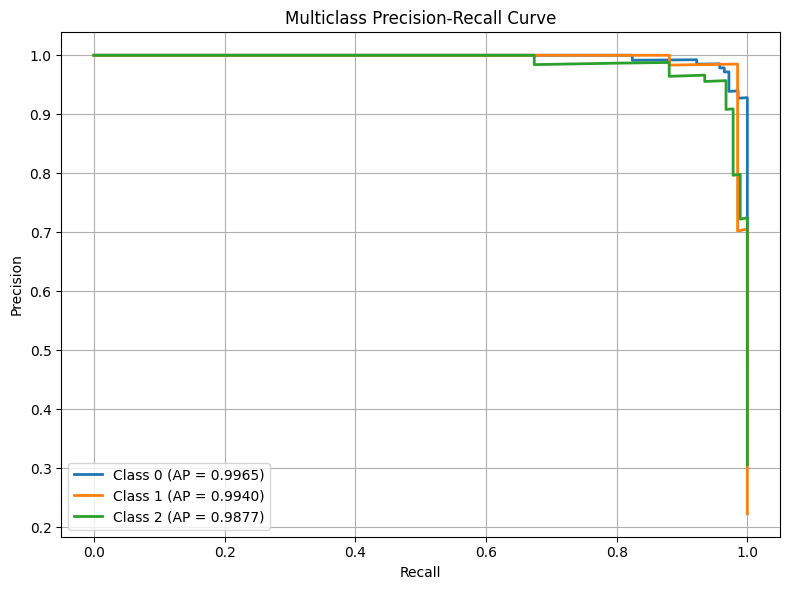

In [54]:
plt.figure(figsize=(8, 6))

for i in range(num_classes):
    precision_vals, recall_vals, _ = precision_recall_curve(y_bin[:, i], all_probs[:, i])
    ap_score = average_precision_score(y_bin[:, i], all_probs[:, i])
    plt.plot(recall_vals, precision_vals, linewidth=2, label=f"Class {i} (AP = {ap_score:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Multiclass Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(True)
plt.tight_layout()
plt.show()

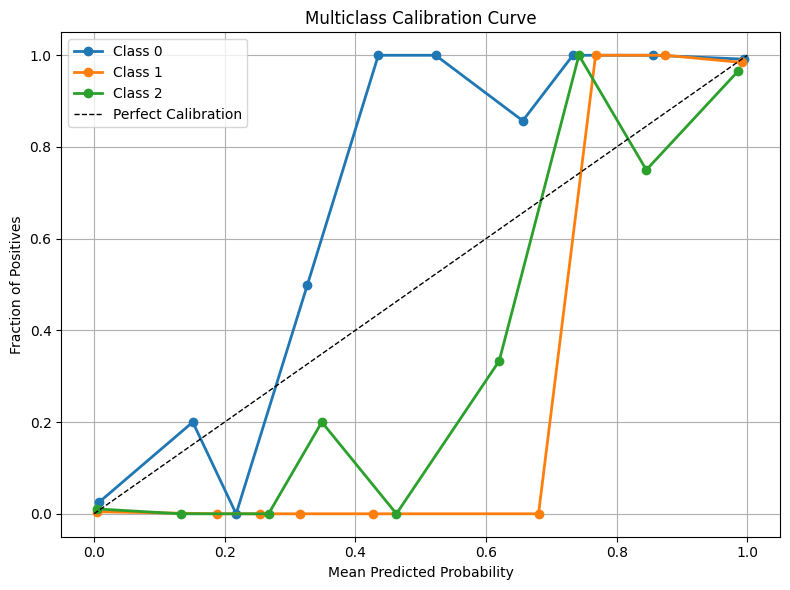

In [55]:
plt.figure(figsize=(8, 6))

for i in range(num_classes):
    prob_true, prob_pred = calibration_curve(y_bin[:, i], all_probs[:, i], n_bins=10, strategy='uniform')
    plt.plot(prob_pred, prob_true, marker='o', linewidth=2, label=f"Class {i}")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Multiclass Calibration Curve")
plt.legend(loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

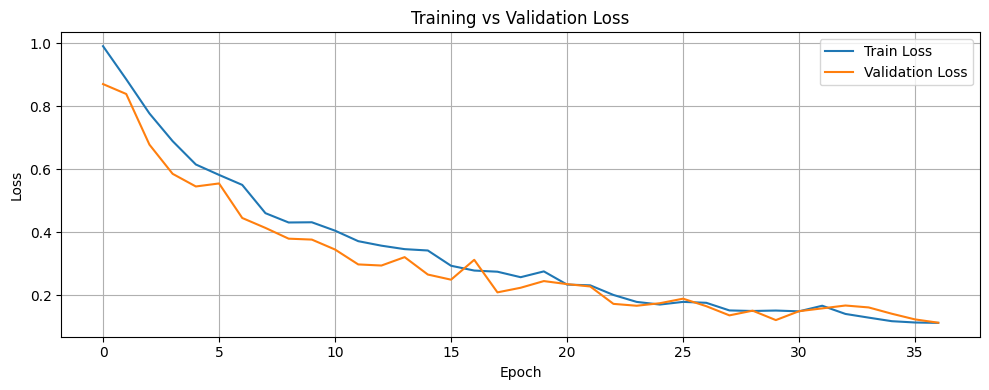

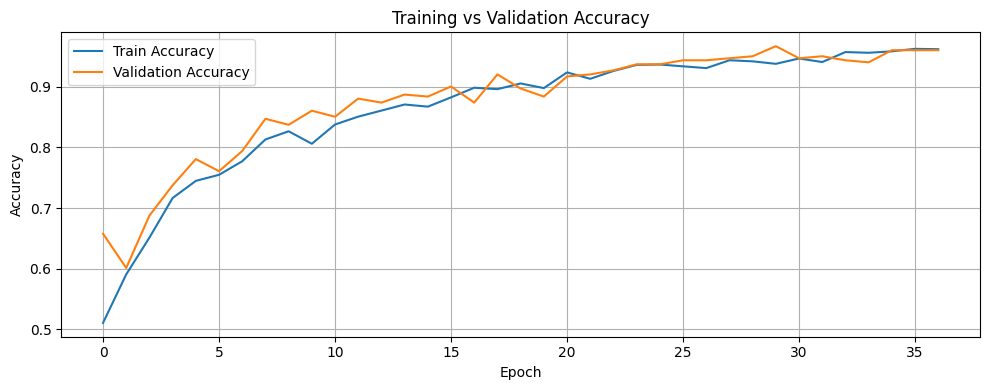

In [56]:
plt.figure(figsize=(10, 4))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs, label='Validation Accuracy')
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Number of feature names: 9
Model input features    : 9
Train shape: (1701, 9)
Test shape : (301, 9)
Background shape: (50, 9)
Test sample shape: (20, 9)


  0%|          | 0/20 [00:00<?, ?it/s]

Type of shap_values: <class 'numpy.ndarray'>
Detected array output from SHAP
SHAP values shape: (20, 9, 3)
Length of mean_abs_shap: 9
Length of feature_names: 9

SHAP Feature Importance Table:


,Feature,Mean_Abs_SHAP
6,Feeling anxious,0.098165
1,Feeling sad or Tearful,0.077901
4,Problems concentrating or making decision,0.074711
3,Trouble sleeping at night,0.066047
7,Feeling of guilt,0.065867
5,Overeating or loss of appetite,0.062153
2,Irritable towards baby & partner,0.054419
8,Problems of bonding with baby,0.042575
0,Age,0.036563


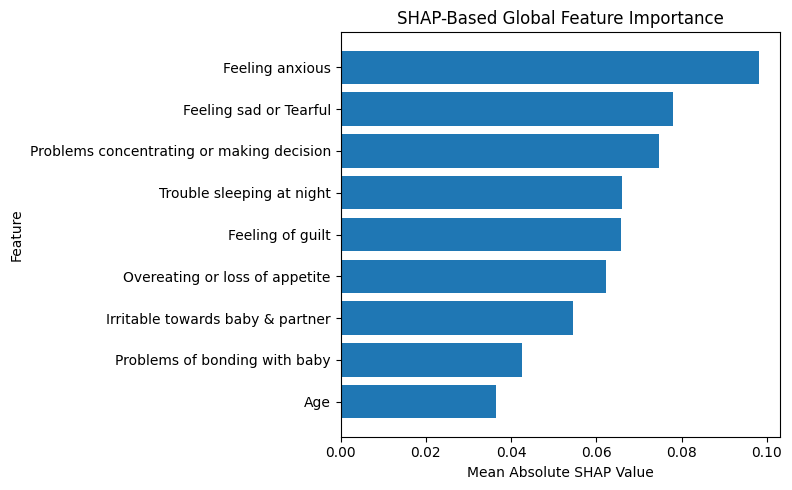


Generating SHAP summary plot...


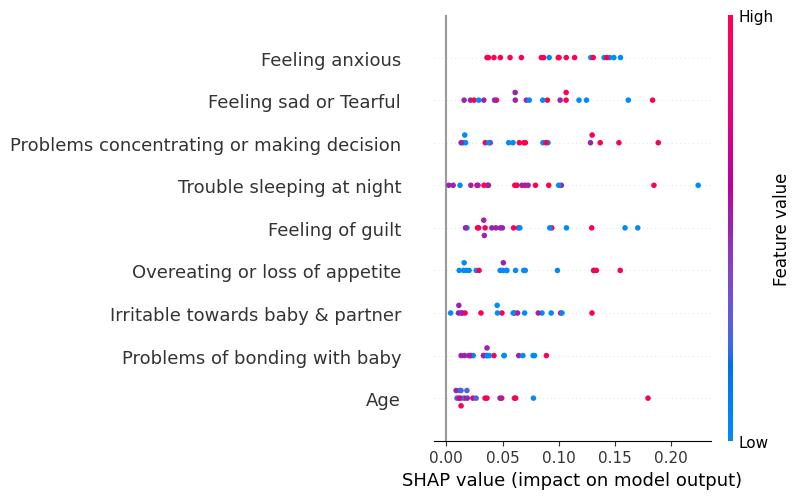


Generating class-wise summary plots...

Class 0


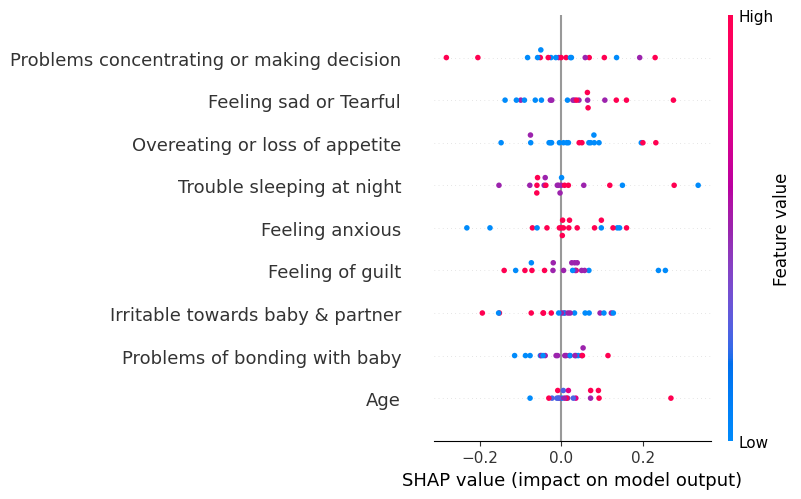


Class 1


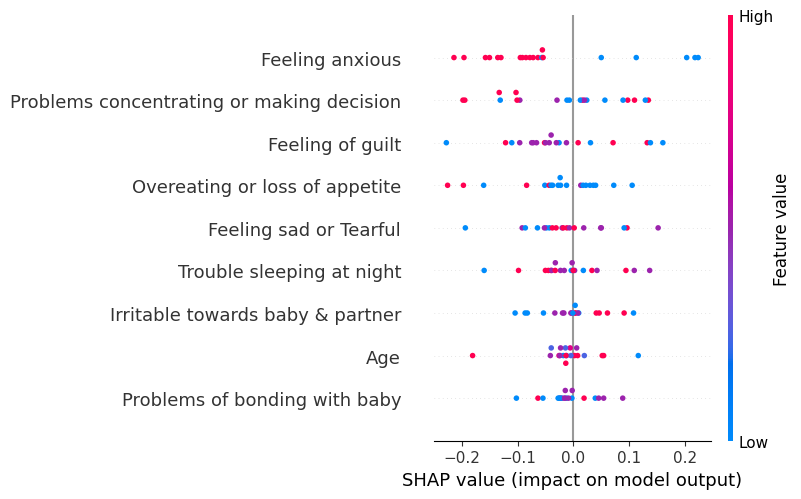


Class 2


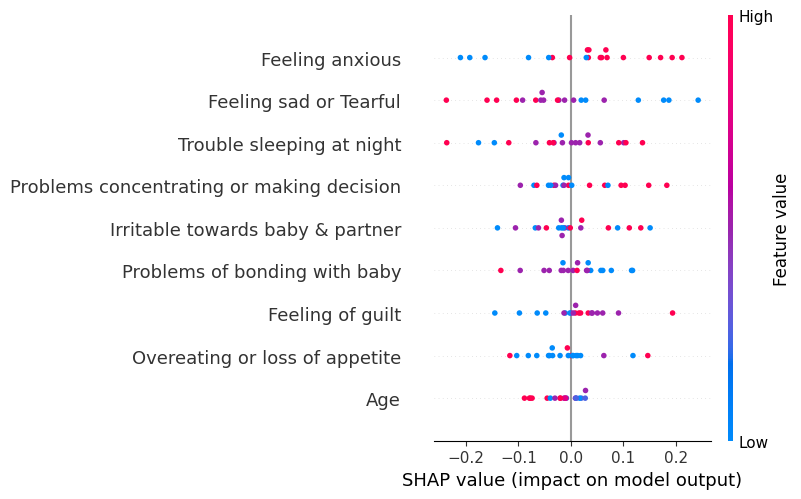


Top Feature: Feeling anxious


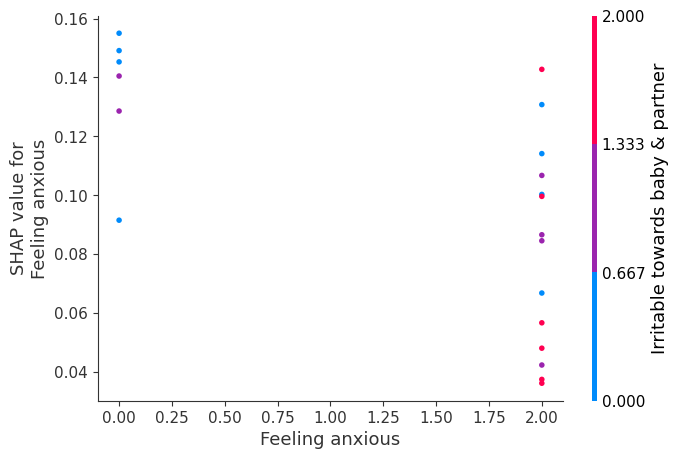


Saved: shap_feature_importance_ppd.csv


In [57]:
!pip install -q shap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import torch

# =========================
# 1. Prepare correct feature names
# =========================
if hasattr(X_train_res, "columns"):
    feature_names = X_train_res.columns.tolist()
else:
    feature_names = [f"Feature_{i+1}" for i in range(X_train_tensor.shape[1])]

print("Number of feature names:", len(feature_names))
print("Model input features    :", X_train_tensor.shape[1])

# =========================
# 2. Prepare numeric arrays
# =========================
X_train_np = X_train_tensor.numpy().astype(np.float32)
X_test_np  = X_test_tensor.numpy().astype(np.float32)
y_test_np  = y_test_tensor.numpy()

print("Train shape:", X_train_np.shape)
print("Test shape :", X_test_np.shape)

# =========================
# 3. SHAP prediction function
# =========================
def shap_predict(X_input):
    model.eval()
    X_tensor = torch.tensor(X_input, dtype=torch.float32).to(device)

    with torch.no_grad():
        outputs = model(X_tensor)
        probs = torch.softmax(outputs, dim=1).cpu().numpy()

    return probs

# =========================
# 4. Small subsets for speed
# =========================
background_size = min(50, len(X_train_np))
test_sample_size = min(20, len(X_test_np))

np.random.seed(42)
background_idx = np.random.choice(len(X_train_np), background_size, replace=False)
test_idx = np.random.choice(len(X_test_np), test_sample_size, replace=False)

background_data = X_train_np[background_idx]
test_sample = X_test_np[test_idx]

print("Background shape:", background_data.shape)
print("Test sample shape:", test_sample.shape)

# =========================
# 5. SHAP explainer
# =========================
explainer = shap.KernelExplainer(shap_predict, background_data)
shap_values = explainer.shap_values(test_sample, nsamples=50)

print("Type of shap_values:", type(shap_values))

# =========================
# 6. Normalize SHAP output
# =========================
if isinstance(shap_values, list):
    print("Detected list output from SHAP")
    for i, sv in enumerate(shap_values):
        print(f"Class {i} shape: {np.array(sv).shape}")

    mean_abs_shap = np.mean([np.abs(sv) for sv in shap_values], axis=(0, 1))
    shap_agg = np.mean(np.abs(np.array(shap_values)), axis=0)  # (samples, features)

else:
    shap_values = np.array(shap_values)
    print("Detected array output from SHAP")
    print("SHAP values shape:", shap_values.shape)

    # Expected shape: (samples, features, classes)
    mean_abs_shap = np.mean(np.abs(shap_values), axis=(0, 2))
    shap_agg = np.mean(np.abs(shap_values), axis=2)  # (samples, features)

print("Length of mean_abs_shap:", len(mean_abs_shap))
print("Length of feature_names:", len(feature_names))

# Safety alignment
if len(feature_names) != len(mean_abs_shap):
    feature_names = [f"Feature_{i+1}" for i in range(len(mean_abs_shap))]
    print("Feature names reset to generic names due to length mismatch.")

# =========================
# 7. Importance table
# =========================
shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_SHAP": mean_abs_shap
}).sort_values(by="Mean_Abs_SHAP", ascending=False)

print("\nSHAP Feature Importance Table:")
display(shap_importance_df)

# =========================
# 8. Global bar plot
# =========================
plt.figure(figsize=(8, 5))
plt.barh(shap_importance_df["Feature"], shap_importance_df["Mean_Abs_SHAP"])
plt.gca().invert_yaxis()
plt.title("SHAP-Based Global Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# =========================
# 9. Summary plot
# =========================
print("\nGenerating SHAP summary plot...")
shap.summary_plot(
    shap_agg,
    test_sample,
    feature_names=feature_names,
    show=True
)

# =========================
# 10. Class-wise summary plots
# =========================
print("\nGenerating class-wise summary plots...")

if isinstance(shap_values, list):
    for class_idx in range(len(shap_values)):
        print(f"\nClass {class_idx}")
        shap.summary_plot(
            shap_values[class_idx],
            test_sample,
            feature_names=feature_names,
            show=True
        )
else:
    num_classes = shap_values.shape[2]
    for class_idx in range(num_classes):
        print(f"\nClass {class_idx}")
        shap.summary_plot(
            shap_values[:, :, class_idx],
            test_sample,
            feature_names=feature_names,
            show=True
        )

# =========================
# 11. Dependence plot for top feature
# =========================
top_feature = shap_importance_df.iloc[0]["Feature"]
top_feature_index = feature_names.index(top_feature)

print("\nTop Feature:", top_feature)

try:
    if isinstance(shap_values, list):
        shap.dependence_plot(
            top_feature_index,
            shap_values[0],
            test_sample,
            feature_names=feature_names
        )
    else:
        shap.dependence_plot(
            top_feature_index,
            shap_agg,
            test_sample,
            feature_names=feature_names
        )
except Exception as e:
    print("Dependence plot could not be generated:", e)

# =========================
# 12. Save importance
# =========================
shap_importance_df.to_csv("shap_feature_importance_ppd.csv", index=False)
print("\nSaved: shap_feature_importance_ppd.csv")

In [58]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score
)
from imblearn.over_sampling import SMOTE

# =========================================
# 1. Dataset for PyTorch
# =========================================
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# =========================================
# 2. Model
# =========================================
class ResidualBlock(nn.Module):
    def __init__(self, dim, dropout=0.2):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, dim * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim * 2, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return x + self.block(x)


class FeatureTokenizerNet(nn.Module):
    def __init__(self, input_dim, num_classes, emb_dim=128, num_blocks=5, dropout=0.25):
        super().__init__()

        self.feature_proj = nn.Sequential(
            nn.Linear(input_dim, emb_dim),
            nn.LayerNorm(emb_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        self.res_blocks = nn.Sequential(
            *[ResidualBlock(emb_dim, dropout=dropout) for _ in range(num_blocks)]
        )

        self.gate = nn.Sequential(
            nn.Linear(emb_dim, emb_dim),
            nn.Sigmoid()
        )

        self.head = nn.Sequential(
            nn.LayerNorm(emb_dim),
            nn.Linear(emb_dim, emb_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(emb_dim // 2, num_classes)
        )

    def forward(self, x):
        x = self.feature_proj(x)
        x = self.res_blocks(x)
        g = self.gate(x)
        x = x * g
        x = self.head(x)
        return x


# =========================================
# 3. Reproducibility
# =========================================
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


# =========================================
# 4. Prepare full encoded data
#    Use your final numeric dataframe only
# =========================================
# Example:
# X_all = df_model.drop(columns=[target_column]).values.astype(np.float32)
# y_all = df_model[target_column].values.astype(np.int64)

X_all = df_model.drop(columns=[target_column]).values.astype(np.float32)
y_all = df_model[target_column].values.astype(np.int64)

print("Full X shape:", X_all.shape)
print("Full y shape:", y_all.shape)

input_dim = X_all.shape[1]
num_classes = len(np.unique(y_all))
print("Input dim:", input_dim)
print("Num classes:", num_classes)


# =========================================
# 5. Device
# =========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


# =========================================
# 6. K-Fold setup
# =========================================
n_splits = 5
batch_size = 32
num_epochs = 50
patience = 7

skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

fold_results = []


# =========================================
# 7. K-Fold training
# =========================================
for fold, (train_idx, val_idx) in enumerate(skf.split(X_all, y_all), 1):
    print(f"\n{'='*20} Fold {fold}/{n_splits} {'='*20}")

    # Split
    X_train_fold = X_all[train_idx]
    y_train_fold = y_all[train_idx]
    X_val_fold = X_all[val_idx]
    y_val_fold = y_all[val_idx]

    print("Before SMOTE:", np.bincount(y_train_fold))

    # SMOTE only on training fold
    smote = SMOTE(random_state=42)
    X_train_fold, y_train_fold = smote.fit_resample(X_train_fold, y_train_fold)

    print("After SMOTE :", np.bincount(y_train_fold))

    # Tensors
    X_train_tensor = torch.tensor(X_train_fold, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train_fold, dtype=torch.long)
    X_val_tensor = torch.tensor(X_val_fold, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val_fold, dtype=torch.long)

    # Loaders
    train_dataset = TabularDataset(X_train_tensor, y_train_tensor)
    val_dataset = TabularDataset(X_val_tensor, y_val_tensor)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    # Fresh model each fold
    model = FeatureTokenizerNet(
        input_dim=input_dim,
        num_classes=num_classes,
        emb_dim=128,
        num_blocks=5,
        dropout=0.25
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=0.0008, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', patience=3, factor=0.5
    )

    best_val_acc = 0.0
    best_preds = None
    best_labels = None
    patience_counter = 0

    fold_train_losses = []
    fold_val_losses = []
    fold_train_accs = []
    fold_val_accs = []

    for epoch in range(num_epochs):
        # ---------------- TRAIN ----------------
        model.train()
        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()

            running_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            correct_train += (preds == yb).sum().item()
            total_train += yb.size(0)

        train_loss = running_loss / len(train_loader)
        train_acc = correct_train / total_train

        # ---------------- VALIDATION ----------------
        model.eval()
        running_val_loss = 0.0
        correct_val = 0
        total_val = 0

        all_fold_preds = []
        all_fold_labels = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)

                outputs = model(xb)
                loss = criterion(outputs, yb)

                running_val_loss += loss.item()
                preds = torch.argmax(outputs, dim=1)

                correct_val += (preds == yb).sum().item()
                total_val += yb.size(0)

                all_fold_preds.extend(preds.cpu().numpy())
                all_fold_labels.extend(yb.cpu().numpy())

        val_loss = running_val_loss / len(val_loader)
        val_acc = correct_val / total_val

        fold_train_losses.append(train_loss)
        fold_val_losses.append(val_loss)
        fold_train_accs.append(train_acc)
        fold_val_accs.append(val_acc)

        scheduler.step(val_acc)

        print(
            f"Fold {fold} | Epoch [{epoch+1}/{num_epochs}] | "
            f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
        )

        # Save best fold model stats
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_preds = np.array(all_fold_preds)
            best_labels = np.array(all_fold_labels)
            best_state = model.state_dict()
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping in fold {fold}")
            break

    # Restore best fold model
    model.load_state_dict(best_state)

    # Fold metrics
    fold_acc = accuracy_score(best_labels, best_preds)
    fold_prec = precision_score(best_labels, best_preds, average='weighted', zero_division=0)
    fold_rec = recall_score(best_labels, best_preds, average='weighted', zero_division=0)
    fold_f1 = f1_score(best_labels, best_preds, average='weighted', zero_division=0)
    fold_f1_macro = f1_score(best_labels, best_preds, average='macro', zero_division=0)
    fold_bal_acc = balanced_accuracy_score(best_labels, best_preds)
    fold_mcc = matthews_corrcoef(best_labels, best_preds)
    fold_kappa = cohen_kappa_score(best_labels, best_preds)

    fold_results.append({
        "Fold": fold,
        "Accuracy": fold_acc,
        "Precision_weighted": fold_prec,
        "Recall_weighted": fold_rec,
        "F1_weighted": fold_f1,
        "F1_macro": fold_f1_macro,
        "Balanced_Accuracy": fold_bal_acc,
        "MCC": fold_mcc,
        "Cohen_Kappa": fold_kappa,
        "Best_Val_Accuracy": best_val_acc
    })

    print(f"\nFold {fold} Best Metrics")
    print(f"Accuracy           : {fold_acc:.4f}")
    print(f"Precision weighted : {fold_prec:.4f}")
    print(f"Recall weighted    : {fold_rec:.4f}")
    print(f"F1 weighted        : {fold_f1:.4f}")
    print(f"F1 macro           : {fold_f1_macro:.4f}")
    print(f"Balanced Accuracy  : {fold_bal_acc:.4f}")
    print(f"MCC                : {fold_mcc:.4f}")
    print(f"Cohen Kappa        : {fold_kappa:.4f}")


# =========================================
# 8. Final results table
# =========================================
results_df = pd.DataFrame(fold_results)
print("\nPer-fold Results")
display(results_df)

mean_row = results_df.drop(columns=["Fold"]).mean()
std_row = results_df.drop(columns=["Fold"]).std()

summary_df = pd.DataFrame({
    "Metric": mean_row.index,
    "Mean": mean_row.values,
    "Std": std_row.values
})

print("\nK-Fold Summary")
display(summary_df)

Full X shape: (1503, 9)
Full y shape: (1503,)
Input dim: 9
Num classes: 3
Using device: cpu

==================== Fold 1/5 ====================
Before SMOTE: [567 268 367]
After SMOTE : [567 567 567]
Fold 1 | Epoch [1/50] | Train Loss: 0.9758 | Train Acc: 0.5197 | Val Loss: 0.8223 | Val Acc: 0.5681
Fold 1 | Epoch [2/50] | Train Loss: 0.8307 | Train Acc: 0.6079 | Val Loss: 0.7071 | Val Acc: 0.6478
Fold 1 | Epoch [3/50] | Train Loss: 0.7290 | Train Acc: 0.6702 | Val Loss: 0.6144 | Val Acc: 0.7010
Fold 1 | Epoch [4/50] | Train Loss: 0.6489 | Train Acc: 0.7102 | Val Loss: 0.5511 | Val Acc: 0.7641
Fold 1 | Epoch [5/50] | Train Loss: 0.5909 | Train Acc: 0.7402 | Val Loss: 0.5244 | Val Acc: 0.7542
Fold 1 | Epoch [6/50] | Train Loss: 0.5619 | Train Acc: 0.7484 | Val Loss: 0.4673 | Val Acc: 0.8173
Fold 1 | Epoch [7/50] | Train Loss: 0.5233 | Train Acc: 0.7801 | Val Loss: 0.4438 | Val Acc: 0.8339
Fold 1 | Epoch [8/50] | Train Loss: 0.4666 | Train Acc: 0.7989 | Val Loss: 0.4614 | Val Acc: 0.8173


,Fold,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_Accuracy,MCC,Cohen_Kappa,Best_Val_Accuracy
0,1,0.973422,0.974257,0.973422,0.973527,0.975624,0.977317,0.958590,0.958237,0.973422
1,2,0.976744,0.976777,0.976744,0.976746,0.973762,0.973133,0.963332,0.963314,0.976744
2,3,0.933555,0.934819,0.933555,0.933276,0.930193,0.925575,0.895546,0.894864,0.933555
3,4,0.930000,0.931032,0.930000,0.928730,0.919691,0.916411,0.890887,0.889454,0.930000
4,5,0.976667,0.976725,0.976667,0.976675,0.976331,0.975681,0.963202,0.963185,0.976667



K-Fold Summary


,Metric,Mean,Std
0,Accuracy,0.958078,0.024079
1,Precision_weighted,0.958722,0.023609
2,Recall_weighted,0.958078,0.024079
3,F1_weighted,0.957791,0.024541
4,F1_macro,0.955120,0.027814
5,Balanced_Accuracy,0.953624,0.030000
6,MCC,0.934311,0.037599
7,Cohen_Kappa,0.933811,0.038126
8,Best_Val_Accuracy,0.958078,0.024079


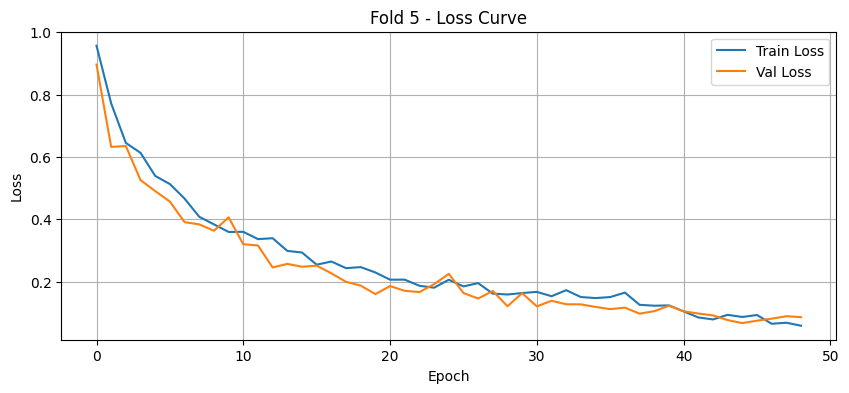

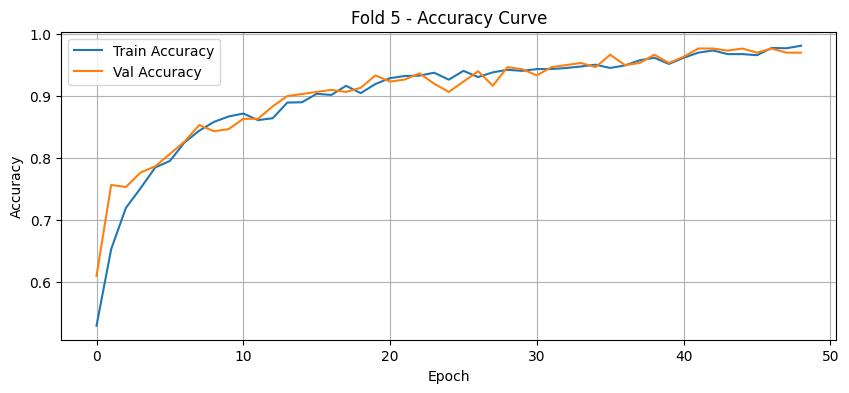

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(fold_train_losses, label="Train Loss")
plt.plot(fold_val_losses, label="Val Loss")
plt.title(f"Fold {fold} - Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(fold_train_accs, label="Train Accuracy")
plt.plot(fold_val_accs, label="Val Accuracy")
plt.title(f"Fold {fold} - Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [60]:
# ============================================================
# BASELINE COMPARISON + PAIRED T-TEST ACROSS FOLDS
# Models:
# 1. Logistic Regression
# 2. Random Forest
# 3. XGBoost
# 4. FeatureTokenizerNet (proposed)
# ============================================================

!pip install -q xgboost imbalanced-learn scipy

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from scipy.stats import ttest_rel

# ============================================================
# 1. Reproducibility
# ============================================================
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# ============================================================
# 2. Prepare full encoded numeric data
# IMPORTANT: df_model and target_column must already exist
# ============================================================
X_all = df_model.drop(columns=[target_column]).values.astype(np.float32)
y_all = df_model[target_column].values.astype(np.int64)

input_dim = X_all.shape[1]
num_classes = len(np.unique(y_all))

print("Full X shape:", X_all.shape)
print("Full y shape:", y_all.shape)
print("Input dim:", input_dim)
print("Num classes:", num_classes)

# ============================================================
# 3. PyTorch dataset
# ============================================================
class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# ============================================================
# 4. Proposed model
# ============================================================
class ResidualBlock(nn.Module):
    def __init__(self, dim, dropout=0.2):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(dim),
            nn.Linear(dim, dim * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(dim * 2, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return x + self.block(x)

class FeatureTokenizerNet(nn.Module):
    def __init__(self, input_dim, num_classes, emb_dim=128, num_blocks=5, dropout=0.25):
        super().__init__()

        self.feature_proj = nn.Sequential(
            nn.Linear(input_dim, emb_dim),
            nn.LayerNorm(emb_dim),
            nn.GELU(),
            nn.Dropout(dropout)
        )

        self.res_blocks = nn.Sequential(
            *[ResidualBlock(emb_dim, dropout=dropout) for _ in range(num_blocks)]
        )

        self.gate = nn.Sequential(
            nn.Linear(emb_dim, emb_dim),
            nn.Sigmoid()
        )

        self.head = nn.Sequential(
            nn.LayerNorm(emb_dim),
            nn.Linear(emb_dim, emb_dim // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(emb_dim // 2, num_classes)
        )

    def forward(self, x):
        x = self.feature_proj(x)
        x = self.res_blocks(x)
        g = self.gate(x)
        x = x * g
        x = self.head(x)
        return x

# ============================================================
# 5. Helper metric function
# ============================================================
def compute_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_weighted": precision_score(y_true, y_pred, average='weighted', zero_division=0),
        "Recall_weighted": recall_score(y_true, y_pred, average='weighted', zero_division=0),
        "F1_weighted": f1_score(y_true, y_pred, average='weighted', zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average='macro', zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen_Kappa": cohen_kappa_score(y_true, y_pred)
    }

# ============================================================
# 6. Proposed model training function
# ============================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def train_feature_tokenizer_model(X_train, y_train, X_val, y_val,
                                  input_dim, num_classes,
                                  batch_size=32, num_epochs=50, patience=7):

    X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)
    X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
    y_val_tensor = torch.tensor(y_val, dtype=torch.long)

    train_dataset = TabularDataset(X_train_tensor, y_train_tensor)
    val_dataset = TabularDataset(X_val_tensor, y_val_tensor)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    model = FeatureTokenizerNet(
        input_dim=input_dim,
        num_classes=num_classes,
        emb_dim=128,
        num_blocks=5,
        dropout=0.25
    ).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=0.0008, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', patience=3, factor=0.5
    )

    best_val_acc = 0.0
    patience_counter = 0
    best_preds = None
    best_labels = None
    best_state = None

    for epoch in range(num_epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()

        model.eval()
        all_preds = []
        all_labels = []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                outputs = model(xb)
                preds = torch.argmax(outputs, dim=1)

                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(yb.cpu().numpy())

        val_acc = accuracy_score(all_labels, all_preds)
        scheduler.step(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_preds = np.array(all_preds)
            best_labels = np.array(all_labels)
            best_state = model.state_dict()
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return best_labels, best_preds, best_val_acc

# ============================================================
# 7. K-fold evaluation for all models
# ============================================================
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

fold_rows = []

acc_scores = {
    "Logistic Regression": [],
    "Random Forest": [],
    "XGBoost": [],
    "FeatureTokenizerNet": []
}

for fold, (train_idx, val_idx) in enumerate(skf.split(X_all, y_all), 1):
    print(f"\n{'='*20} Fold {fold}/{n_splits} {'='*20}")

    X_train = X_all[train_idx]
    y_train = y_all[train_idx]
    X_val = X_all[val_idx]
    y_val = y_all[val_idx]

    print("Before SMOTE:", np.bincount(y_train))

    smote = SMOTE(random_state=42)
    X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

    print("After SMOTE :", np.bincount(y_train_sm))

    # -----------------------------
    # Logistic Regression
    # -----------------------------
    lr_model = LogisticRegression(
        max_iter=2000,
        multi_class='auto',
        random_state=42
    )
    lr_model.fit(X_train_sm, y_train_sm)
    lr_preds = lr_model.predict(X_val)
    lr_metrics = compute_metrics(y_val, lr_preds)
    acc_scores["Logistic Regression"].append(lr_metrics["Accuracy"])

    fold_rows.append({
        "Fold": fold,
        "Model": "Logistic Regression",
        **lr_metrics
    })

    # -----------------------------
    # Random Forest
    # -----------------------------
    rf_model = RandomForestClassifier(
        n_estimators=150,
        max_depth=6,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )
    rf_model.fit(X_train_sm, y_train_sm)
    rf_preds = rf_model.predict(X_val)
    rf_metrics = compute_metrics(y_val, rf_preds)
    acc_scores["Random Forest"].append(rf_metrics["Accuracy"])

    fold_rows.append({
        "Fold": fold,
        "Model": "Random Forest",
        **rf_metrics
    })

    # -----------------------------
    # XGBoost
    # -----------------------------
    xgb_model = XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.7,
        colsample_bytree=0.7,
        gamma=1.0,
        reg_alpha=0.5,
        reg_lambda=1.0,
        objective='multi:softmax',
        num_class=num_classes,
        eval_metric='mlogloss',
        random_state=42
    )
    xgb_model.fit(X_train_sm, y_train_sm)
    xgb_preds = xgb_model.predict(X_val)
    xgb_metrics = compute_metrics(y_val, xgb_preds)
    acc_scores["XGBoost"].append(xgb_metrics["Accuracy"])

    fold_rows.append({
        "Fold": fold,
        "Model": "XGBoost",
        **xgb_metrics
    })

    # -----------------------------
    # FeatureTokenizerNet
    # -----------------------------
    ft_labels, ft_preds, ft_best_acc = train_feature_tokenizer_model(
        X_train_sm, y_train_sm, X_val, y_val,
        input_dim=input_dim,
        num_classes=num_classes,
        batch_size=32,
        num_epochs=50,
        patience=7
    )
    ft_metrics = compute_metrics(ft_labels, ft_preds)
    acc_scores["FeatureTokenizerNet"].append(ft_metrics["Accuracy"])

    fold_rows.append({
        "Fold": fold,
        "Model": "FeatureTokenizerNet",
        **ft_metrics
    })

    print(f"Fold {fold} summary:")
    print(f"  LR  Accuracy: {lr_metrics['Accuracy']:.4f}")
    print(f"  RF  Accuracy: {rf_metrics['Accuracy']:.4f}")
    print(f"  XGB Accuracy: {xgb_metrics['Accuracy']:.4f}")
    print(f"  FTN Accuracy: {ft_metrics['Accuracy']:.4f}")

# ============================================================
# 8. Per-fold results
# ============================================================
results_df = pd.DataFrame(fold_rows)
print("\nPer-fold baseline comparison:")
display(results_df)

# ============================================================
# 9. Mean ± std summary
# ============================================================
summary_df = (
    results_df
    .groupby("Model")
    .agg(["mean", "std"])
    .reset_index()
)

print("\nMean ± Std summary:")
display(summary_df)

metrics = [
    "Accuracy", "Precision_weighted", "Recall_weighted", "F1_weighted",
    "F1_macro", "Balanced_Accuracy", "MCC", "Cohen_Kappa"
]

summary_rows = []
for model_name in results_df["Model"].unique():
    sub = results_df[results_df["Model"] == model_name]
    row = {"Model": model_name}
    for m in metrics:
        row[m] = f"{sub[m].mean():.4f} ± {sub[m].std():.4f}"
    summary_rows.append(row)

summary_clean_df = pd.DataFrame(summary_rows)
print("\nPaper-ready summary table:")
display(summary_clean_df)

# ============================================================
# 10. Paired t-tests across folds (Accuracy)
# ============================================================
proposed = np.array(acc_scores["FeatureTokenizerNet"])
lr_acc = np.array(acc_scores["Logistic Regression"])
rf_acc = np.array(acc_scores["Random Forest"])
xgb_acc = np.array(acc_scores["XGBoost"])

ttest_rows = []

for baseline_name, baseline_scores in [
    ("Logistic Regression", lr_acc),
    ("Random Forest", rf_acc),
    ("XGBoost", xgb_acc)
]:
    t_stat, p_val = ttest_rel(proposed, baseline_scores)
    ttest_rows.append({
        "Comparison": f"FeatureTokenizerNet vs {baseline_name}",
        "Proposed Mean Accuracy": proposed.mean(),
        "Baseline Mean Accuracy": baseline_scores.mean(),
        "t-statistic": t_stat,
        "p-value": p_val,
        "Significant (p < 0.05)": "Yes" if p_val < 0.05 else "No"
    })

ttest_df = pd.DataFrame(ttest_rows)
print("\nPaired t-test results (Accuracy across folds):")
display(ttest_df)

# ============================================================
# 11. Paired t-tests for weighted F1
# ============================================================
f1_scores = {}
for model_name in results_df["Model"].unique():
    f1_scores[model_name] = results_df[results_df["Model"] == model_name]["F1_weighted"].values

proposed_f1 = np.array(f1_scores["FeatureTokenizerNet"])

ttest_f1_rows = []
for baseline_name in ["Logistic Regression", "Random Forest", "XGBoost"]:
    baseline_f1 = np.array(f1_scores[baseline_name])
    t_stat, p_val = ttest_rel(proposed_f1, baseline_f1)
    ttest_f1_rows.append({
        "Comparison": f"FeatureTokenizerNet vs {baseline_name}",
        "Proposed Mean F1": proposed_f1.mean(),
        "Baseline Mean F1": baseline_f1.mean(),
        "t-statistic": t_stat,
        "p-value": p_val,
        "Significant (p < 0.05)": "Yes" if p_val < 0.05 else "No"
    })

ttest_f1_df = pd.DataFrame(ttest_f1_rows)
print("\nPaired t-test results (Weighted F1 across folds):")
display(ttest_f1_df)

# ============================================================
# 12. Save outputs
# ============================================================
results_df.to_csv("baseline_comparison_per_fold.csv", index=False)
summary_clean_df.to_csv("baseline_comparison_summary.csv", index=False)
ttest_df.to_csv("baseline_ttest_accuracy.csv", index=False)
ttest_f1_df.to_csv("baseline_ttest_f1.csv", index=False)

print("\nSaved files:")
print(" - baseline_comparison_per_fold.csv")
print(" - baseline_comparison_summary.csv")
print(" - baseline_ttest_accuracy.csv")
print(" - baseline_ttest_f1.csv")

Full X shape: (1503, 9)
Full y shape: (1503,)
Input dim: 9
Num classes: 3
Using device: cpu

==================== Fold 1/5 ====================
Before SMOTE: [567 268 367]
After SMOTE : [567 567 567]
Fold 1 summary:
  LR  Accuracy: 0.4618
  RF  Accuracy: 0.8339
  XGB Accuracy: 0.8206
  FTN Accuracy: 0.9734

==================== Fold 2/5 ====================
Before SMOTE: [567 268 367]
After SMOTE : [567 567 567]
Fold 2 summary:
  LR  Accuracy: 0.5449
  RF  Accuracy: 0.8538
  XGB Accuracy: 0.8472
  FTN Accuracy: 0.9767

==================== Fold 3/5 ====================
Before SMOTE: [567 268 367]
After SMOTE : [567 567 567]
Fold 3 summary:
  LR  Accuracy: 0.5449
  RF  Accuracy: 0.8007
  XGB Accuracy: 0.8106
  FTN Accuracy: 0.9336

==================== Fold 4/5 ====================
Before SMOTE: [568 268 367]
After SMOTE : [568 568 568]
Fold 4 summary:
  LR  Accuracy: 0.5433
  RF  Accuracy: 0.7933
  XGB Accuracy: 0.7833
  FTN Accuracy: 0.9300

==================== Fold 5/5 =============

,Fold,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,F1_macro,Balanced_Accuracy,MCC,Cohen_Kappa
0,1,Logistic Regression,0.461794,0.504595,0.461794,0.463254,0.453080,0.473938,0.206578,0.198442
1,1,Random Forest,0.833887,0.844573,0.833887,0.835316,0.828359,0.843671,0.747803,0.743869
2,1,XGBoost,0.820598,0.826032,0.820598,0.821740,0.812297,0.821218,0.722747,0.721124
3,1,FeatureTokenizerNet,0.973422,0.974257,0.973422,0.973527,0.975624,0.977317,0.958590,0.958237
4,2,Logistic Regression,0.544850,0.583680,0.544850,0.547098,0.543127,0.565431,0.327582,0.317652
5,2,Random Forest,0.853821,0.856173,0.853821,0.854465,0.846573,0.852576,0.772035,0.771494
6,2,XGBoost,0.847176,0.847477,0.847176,0.847266,0.843190,0.845329,0.759815,0.759760
7,2,FeatureTokenizerNet,0.976744,0.976777,0.976744,0.976746,0.973762,0.973133,0.963332,0.963314
8,3,Logistic Regression,0.544850,0.571332,0.544850,0.546819,0.542193,0.565736,0.321683,0.314818
9,3,Random Forest,0.800664,0.806220,0.800664,0.800537,0.793932,0.804354,0.693782,0.690801



Mean ± Std summary:


Model Fold            Accuracy           Precision_weighted  \
                       mean       std      mean       std               mean   
0  FeatureTokenizerNet  3.0  1.581139  0.958078  0.024079           0.958722   
1  Logistic Regression  3.0  1.581139  0.516966  0.038799           0.554580   
2        Random Forest  3.0  1.581139  0.824341  0.026112           0.832179   
3              XGBoost  3.0  1.581139  0.818348  0.023756           0.821148   

            Recall_weighted           F1_weighted            F1_macro  \
        std            mean       std        mean       std      mean   
0  0.023609        0.958078  0.024079    0.957791  0.024541  0.955120   
1  0.037993        0.516966  0.038799    0.520323  0.038415  0.511864   
2  0.026025        0.824341  0.026112    0.825353  0.026529  0.814964   
3  0.023829        0.818348  0.023756    0.818842  0.023641  0.807200   

            Balanced_Accuracy                 MCC           Cohen_Kappa  \
        std              mean       std      mean       std        mean   
0  0.027814          0.953624  0.030000  0.934311  0.037599    0.933811   
1  0.042064          0.532828  0.045317  0.284463  0.059638    0.276320   
2  0.028650          0.825067  0.029071  0.730143  0.039442    0.727314   
3  0.029307          0.812022  0.029662  0.716531  0.036999    0.715699   

             
        std  
0  0.038126  
1  0.058090  
2  0.040093  
3  0.036919


Paper-ready summary table:


...


Paired t-test results (Accuracy across folds):


,Comparison,Proposed Mean Accuracy,Baseline Mean Accuracy,t-statistic,p-value,Significant (p < 0.05)
0,FeatureTokenizerNet vs Logistic Regression,0.958078,0.516966,17.406885,0.000064,Yes
1,FeatureTokenizerNet vs Random Forest,0.958078,0.824341,46.084786,0.000001,Yes
2,FeatureTokenizerNet vs XGBoost,0.958078,0.818348,24.446280,0.000017,Yes



Paired t-test results (Weighted F1 across folds):


,Comparison,Proposed Mean F1,Baseline Mean F1,t-statistic,p-value,Significant (p < 0.05)
0,FeatureTokenizerNet vs Logistic Regression,0.957791,0.520323,17.293111,0.000066,Yes
1,FeatureTokenizerNet vs Random Forest,0.957791,0.825353,49.198912,0.000001,Yes
2,FeatureTokenizerNet vs XGBoost,0.957791,0.818842,24.592726,0.000016,Yes



Saved files:
 - baseline_comparison_per_fold.csv
 - baseline_comparison_summary.csv
 - baseline_ttest_accuracy.csv
 - baseline_ttest_f1.csv
